# ODL Assignment 1 - Task 2: Data Preparation (EDA + Preprocessing)
**Dataset:** Airline Passenger Satisfaction  |  **Goal:** predict `satisfaction` (satisfied vs neutral/dissatisfied)

Run this notebook top to bottom in VS Code. Put `train.csv` and `test.csv` in the same folder
(or edit the two paths in the first cell).

**Structure**
- Section 1: Setup and data loading
- Section 2: Exploratory Data Analysis (2.1 - 2.9)
- Section 3: Data Preparation - Step 1 to Step 6
- Section 4: Save the processed data

In [21]:
# SECTION 1 - SETUP -----------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

TRAIN_PATH = "../Dataset/train.csv"
TEST_PATH  = "../Dataset/test.csv"
train = pd.read_csv(TRAIN_PATH)
test  = pd.read_csv(TEST_PATH)
print("Train shape:", train.shape, "| Test shape:", test.shape)

Train shape: (103904, 25) | Test shape: (25976, 25)


## Section 2 - Exploratory Data Analysis (EDA)
Study the data as it arrives, before changing anything, so each later decision is based on evidence.

In [22]:
# 2.1 STRUCTURE ---------------------------------------------------------------
display(train.head())
print(train.dtypes)
display(train.describe())

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,5,3,5,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,1,3,1,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,5,5,5,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,2,2,2,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,4,5,5,3,3,4,4,3,3,3,0,0.0,satisfied


Unnamed: 0                             int64
id                                     int64
Gender                                object
Customer Type                         object
Age                                    int64
Type of Travel                        object
Class                                 object
Flight Distance                        int64
Inflight wifi service                  int64
Departure/Arrival time convenient      int64
Ease of Online booking                 int64
Gate location                          int64
Food and drink                         int64
Online boarding                        int64
Seat comfort                           int64
Inflight entertainment                 int64
On-board service                       int64
Leg room service                       int64
Baggage handling                       int64
Checkin service                        int64
Inflight service                       int64
Cleanliness                            int64
Departure 

,Unnamed: 0,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103594.000000
mean,51951.500000,64924.210502,39.379706,1189.448375,2.729683,3.060296,2.756901,2.976883,3.202129,3.250375,3.439396,3.358158,3.382363,3.351055,3.631833,3.304290,3.640428,3.286351,14.815618,15.178678
std,29994.645522,37463.812252,15.114964,997.147281,1.327829,1.525075,1.398929,1.277621,1.329533,1.349509,1.319088,1.332991,1.288354,1.315605,1.180903,1.265396,1.175663,1.312273,38.230901,38.698682
min,0.000000,1.000000,7.000000,31.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,25975.750000,32533.750000,27.000000,414.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,51951.500000,64856.500000,40.000000,843.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000,4.000000,3.000000,0.000000,0.000000
75%,77927.250000,97368.250000,51.000000,1743.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,4.000000,5.000000,4.000000,5.000000,4.000000,12.000000,13.000000
max,103903.000000,129880.000000,85.000000,4983.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,1592.000000,1584.000000


satisfaction
neutral or dissatisfied    58879
satisfied                  45025
Name: count, dtype: int64
satisfaction
neutral or dissatisfied    56.67
satisfied                  43.33
Name: count, dtype: float64


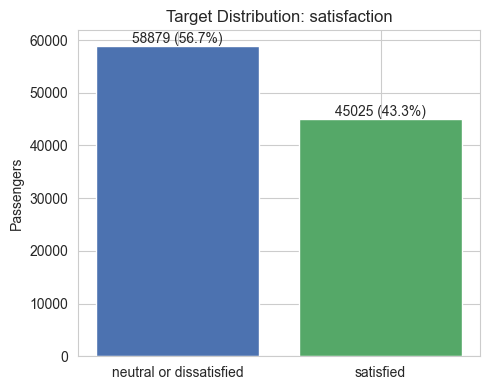

In [23]:
# 2.2 TARGET BALANCE ----------------------------------------------------------
counts = train["satisfaction"].value_counts()
print(counts); print((counts/len(train)*100).round(2))
plt.figure(figsize=(5,4))
plt.bar(counts.index, counts.values, color=["#4C72B0","#55A868"])
plt.title("Target Distribution: satisfaction"); plt.ylabel("Passengers")
for i,v in enumerate(counts.values): plt.text(i,v+500,f"{v} ({v/len(train)*100:.1f}%)",ha="center")
plt.tight_layout(); plt.show()

In [24]:
# 2.3 MISSING VALUES and DUPLICATES ------------------------------------------
missing = train.isna().sum()
print("Missing values per column:\n", missing[missing>0])
print("\nExact duplicate rows (excluding id columns):",
      train.drop(columns=["Unnamed: 0","id"]).duplicated().sum())

Missing values per column:
 Arrival Delay in Minutes    310
dtype: int64

Exact duplicate rows (excluding id columns): 0


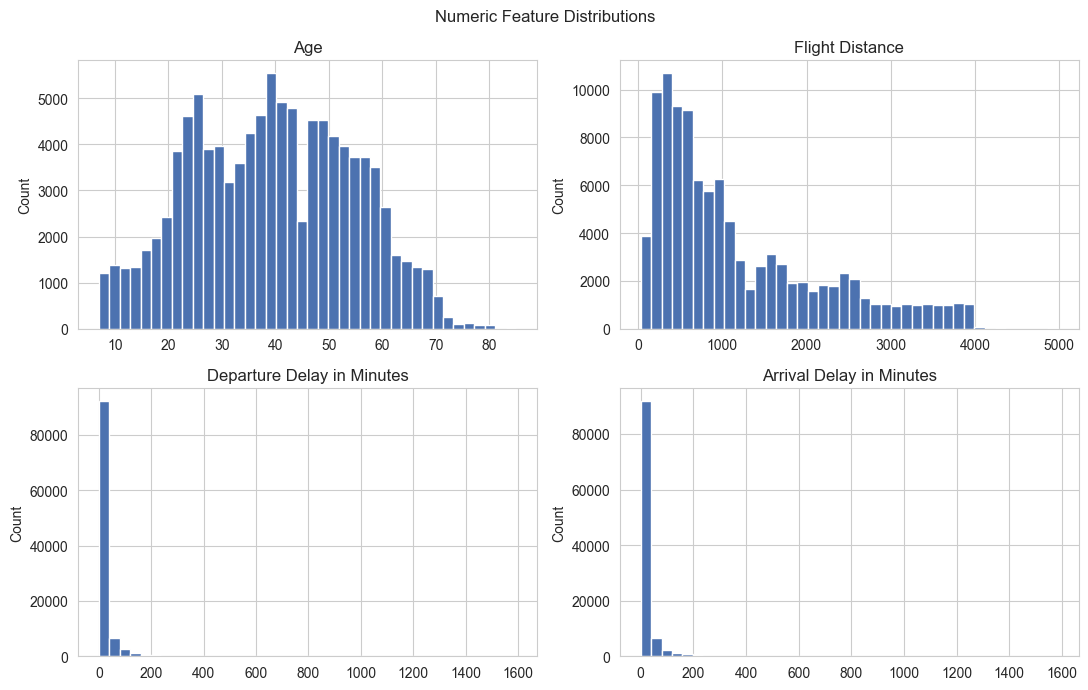

In [25]:
# 2.4 NUMERIC DISTRIBUTIONS ---------------------------------------------------
num=["Age","Flight Distance","Departure Delay in Minutes","Arrival Delay in Minutes"]
fig,ax=plt.subplots(2,2,figsize=(11,7))
for a,col in zip(ax.ravel(),num):
    a.hist(train[col].dropna(),bins=40,color="#4C72B0",edgecolor="white"); a.set_title(col); a.set_ylabel("Count")
plt.suptitle("Numeric Feature Distributions"); plt.tight_layout(); plt.show()

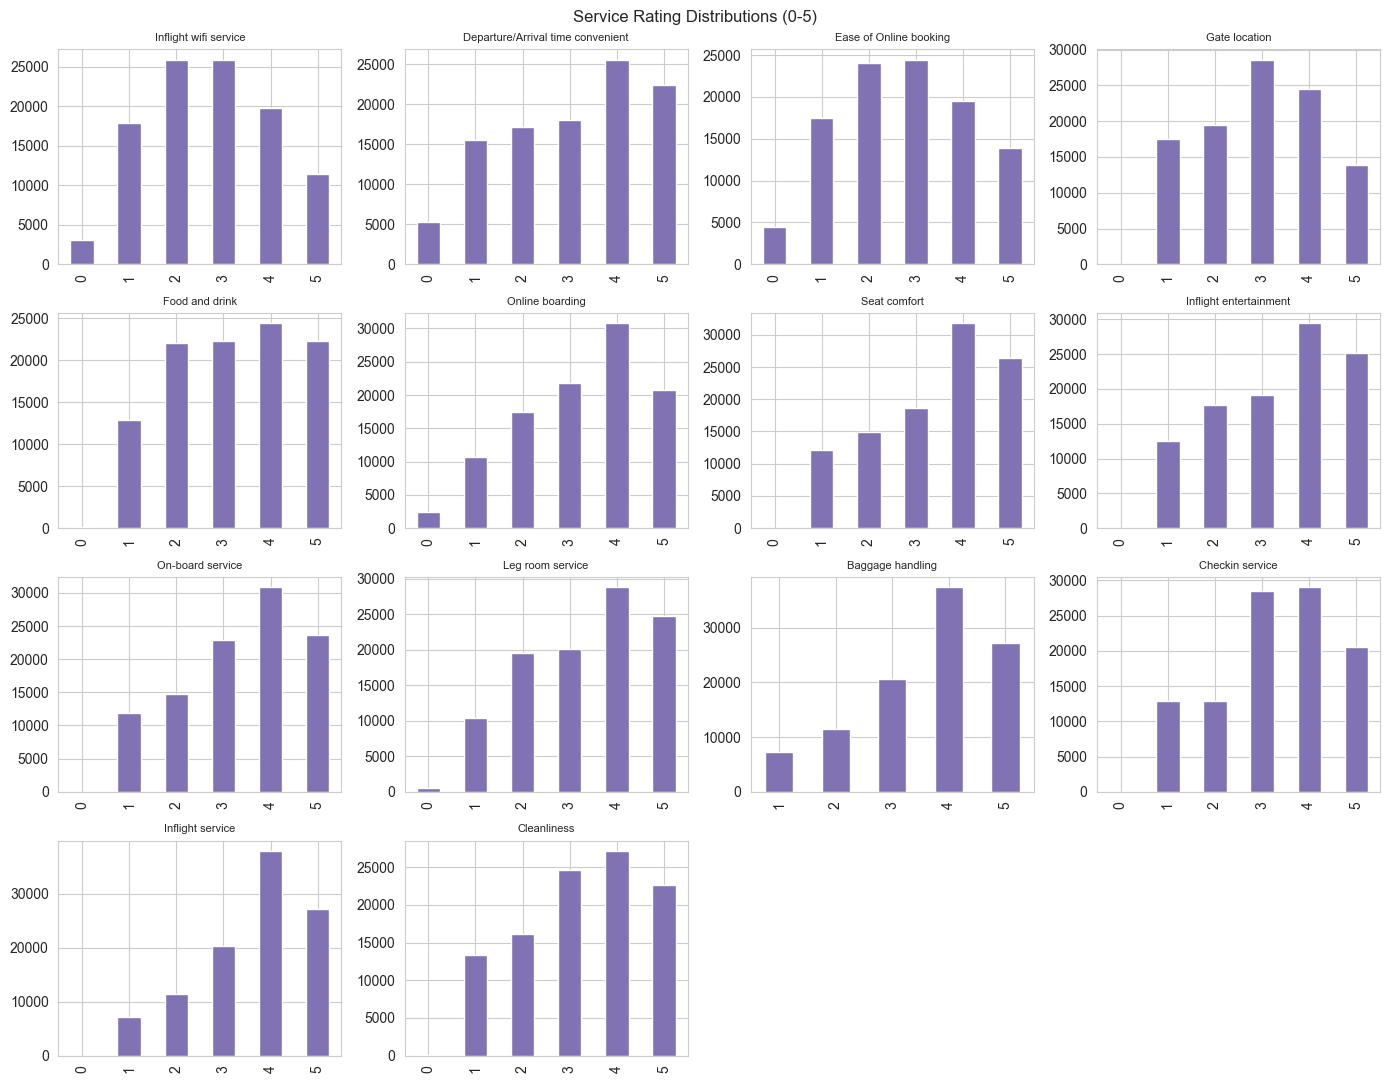

In [26]:
# 2.5 SERVICE RATING DISTRIBUTIONS -------------------------------------------
ratings=["Inflight wifi service","Departure/Arrival time convenient","Ease of Online booking",
         "Gate location","Food and drink","Online boarding","Seat comfort","Inflight entertainment",
         "On-board service","Leg room service","Baggage handling","Checkin service","Inflight service","Cleanliness"]
fig,ax=plt.subplots(4,4,figsize=(14,11))
for a,col in zip(ax.ravel(),ratings):
    train[col].value_counts().sort_index().plot(kind="bar",ax=a,color="#8172B3"); a.set_title(col,fontsize=8); a.set_xlabel("")
for a in ax.ravel()[len(ratings):]: a.axis("off")
plt.suptitle("Service Rating Distributions (0-5)"); plt.tight_layout(); plt.show()

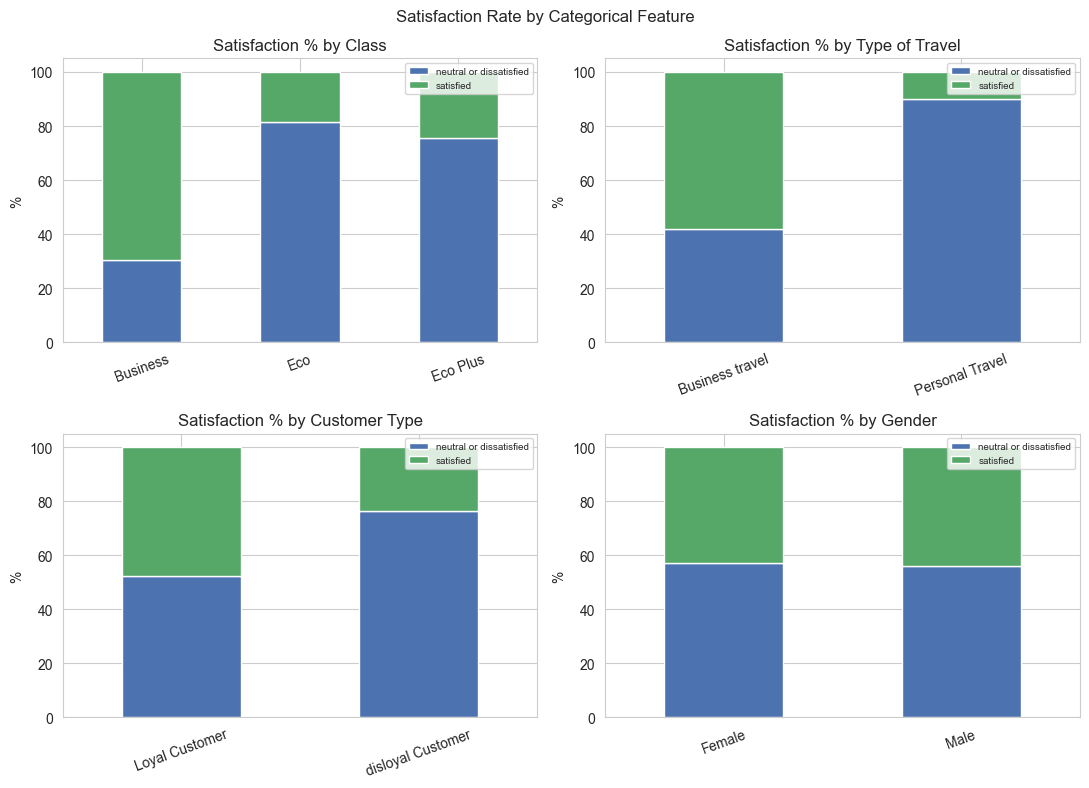

In [27]:
# 2.6 SATISFACTION BY CATEGORY ------------------------------------------------
cats=["Class","Type of Travel","Customer Type","Gender"]
fig,ax=plt.subplots(2,2,figsize=(11,8))
for a,col in zip(ax.ravel(),cats):
    ct=pd.crosstab(train[col],train["satisfaction"],normalize="index")*100
    ct.plot(kind="bar",stacked=True,ax=a,color=["#4C72B0","#55A868"])
    a.set_title(f"Satisfaction % by {col}"); a.set_ylabel("%"); a.legend(fontsize=7); a.set_xlabel(""); a.tick_params(axis="x",rotation=20)
plt.suptitle("Satisfaction Rate by Categorical Feature"); plt.tight_layout(); plt.show()

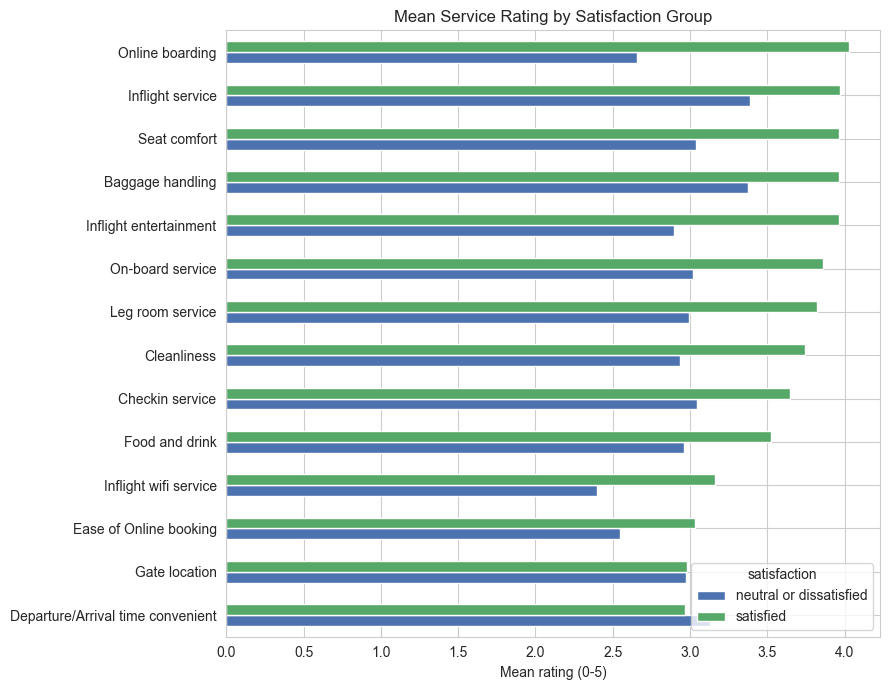

In [28]:
# 2.7 MEAN SERVICE RATING BY SATISFACTION ------------------------------------
means=train.groupby("satisfaction")[ratings].mean().T.sort_values("satisfied")
means.plot(kind="barh",figsize=(9,7),color=["#4C72B0","#55A868"])
plt.xlabel("Mean rating (0-5)"); plt.title("Mean Service Rating by Satisfaction Group"); plt.tight_layout(); plt.show()

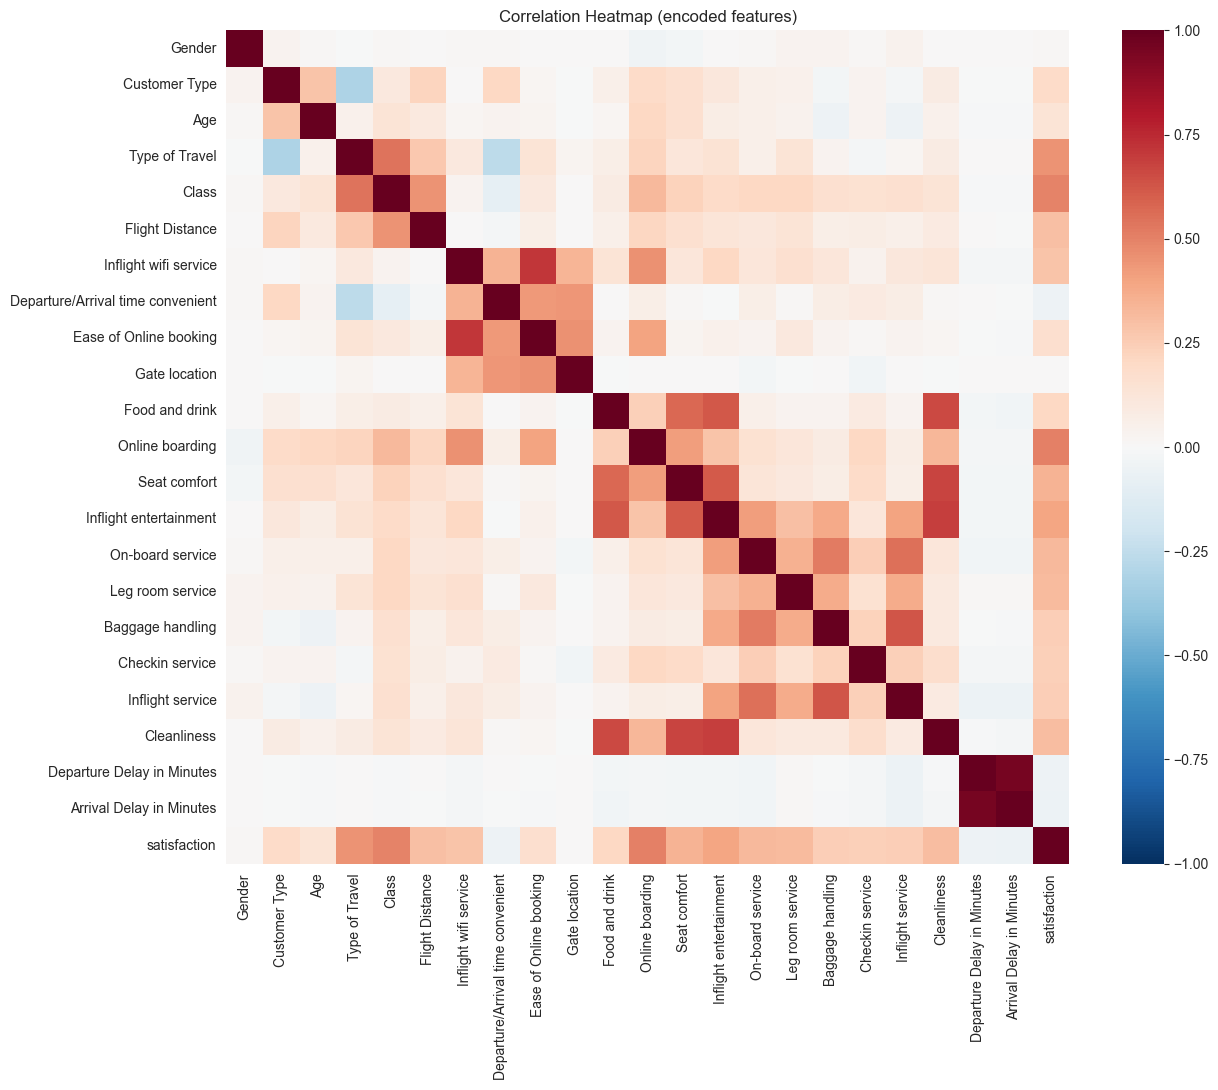

Online boarding                      0.504
Class                                0.494
Type of Travel                       0.449
Inflight entertainment               0.398
Seat comfort                         0.349
On-board service                     0.322
Leg room service                     0.313
Cleanliness                          0.305
Flight Distance                      0.299
Inflight wifi service                0.284
Baggage handling                     0.248
Inflight service                     0.245
Checkin service                      0.236
Food and drink                       0.210
Customer Type                        0.188
Ease of Online booking               0.172
Age                                  0.137
Gender                               0.012
Gate location                        0.001
Departure Delay in Minutes          -0.050
Departure/Arrival time convenient   -0.052
Arrival Delay in Minutes            -0.057
Name: satisfaction, dtype: float64


In [29]:
# 2.8 CORRELATION HEATMAP -----------------------------------------------------
tmp=train.drop(columns=["Unnamed: 0","id"]).copy()
tmp["Arrival Delay in Minutes"]=tmp["Arrival Delay in Minutes"].fillna(tmp["Arrival Delay in Minutes"].median())
tmp["Gender"]=tmp["Gender"].map({"Female":0,"Male":1})
tmp["Customer Type"]=tmp["Customer Type"].map({"disloyal Customer":0,"Loyal Customer":1})
tmp["Type of Travel"]=tmp["Type of Travel"].map({"Personal Travel":0,"Business travel":1})
tmp["Class"]=tmp["Class"].map({"Eco":0,"Eco Plus":1,"Business":2})
tmp["satisfaction"]=tmp["satisfaction"].map({"neutral or dissatisfied":0,"satisfied":1})
plt.figure(figsize=(13,11)); sns.heatmap(tmp.corr(),cmap="RdBu_r",vmin=-1,vmax=1,center=0)
plt.title("Correlation Heatmap (encoded features)"); plt.tight_layout(); plt.show()
print(tmp.corr()["satisfaction"].drop("satisfaction").sort_values(ascending=False).round(3))

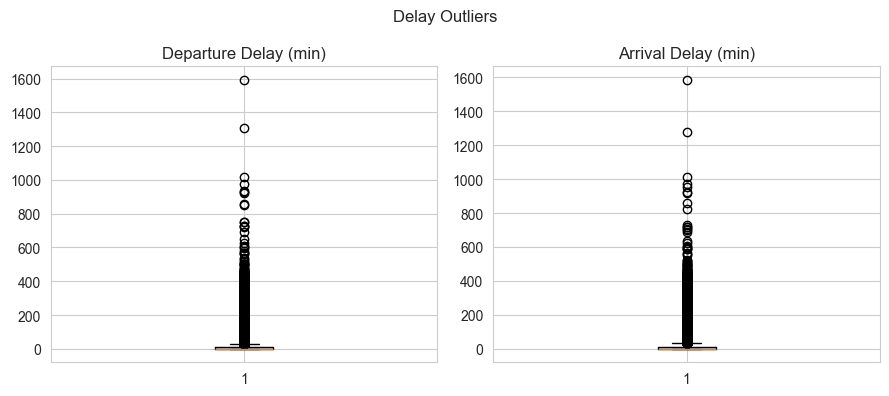

In [30]:
# 2.9 DELAY OUTLIERS ----------------------------------------------------------
fig,ax=plt.subplots(1,2,figsize=(9,4))
ax[0].boxplot(train["Departure Delay in Minutes"].dropna()); ax[0].set_title("Departure Delay (min)")
ax[1].boxplot(train["Arrival Delay in Minutes"].dropna());   ax[1].set_title("Arrival Delay (min)")
plt.suptitle("Delay Outliers"); plt.tight_layout(); plt.show()

Median = 0.0 min | Mean = 15.18 min | Skewness = 6.60
On-time (0 min) = 56.1% of flights | Longest delay = 1584 min


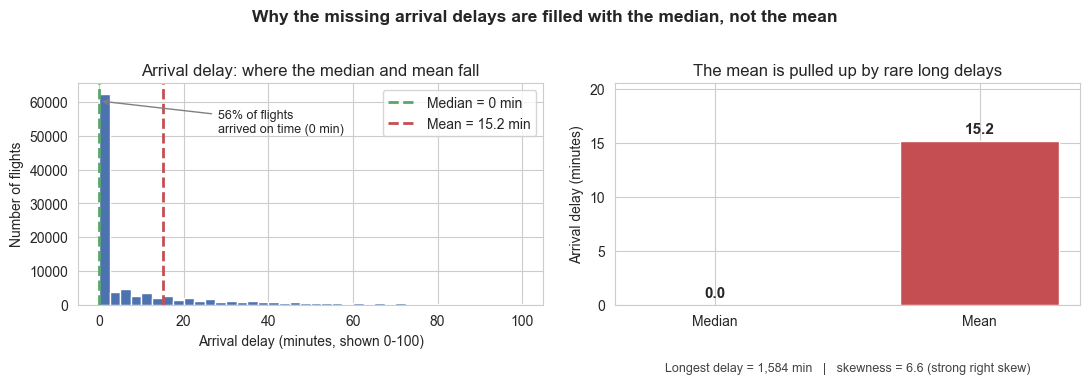

In [31]:
# 2.10 WHY THE MEDIAN IS USED TO FILL MISSING ARRIVAL DELAY (justifies Step 4) -------
# The arrival delay column is the only field with missing values. Because it is heavily
# skewed, the choice between mean and median matters, so it is checked here visually.
ad = train['Arrival Delay in Minutes'].dropna()
med, mean = ad.median(), ad.mean()
sk, mx, pz = ad.skew(), ad.max(), (ad == 0).mean() * 100
print(f'Median = {med:.1f} min | Mean = {mean:.2f} min | Skewness = {sk:.2f}')
print(f'On-time (0 min) = {pz:.1f}% of flights | Longest delay = {mx:.0f} min')

BLUE, RED, GREEN = '#4C72B0', '#C44E52', '#55A868'
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))

cap = 100
ax[0].hist(ad[ad <= cap], bins=40, color=BLUE, edgecolor='white')
ax[0].axvline(med, color=GREEN, linestyle='--', linewidth=2, label=f'Median = {med:.0f} min')
ax[0].axvline(mean, color=RED, linestyle='--', linewidth=2, label=f'Mean = {mean:.1f} min')
ax[0].set_title('Arrival delay: where the median and mean fall')
ax[0].set_xlabel('Arrival delay (minutes, shown 0-100)'); ax[0].set_ylabel('Number of flights')
ax[0].legend(frameon=True)
ax[0].annotate(f'{pz:.0f}% of flights\narrived on time (0 min)',
               xy=(0, ax[0].get_ylim()[1]*0.92), xytext=(28, ax[0].get_ylim()[1]*0.78),
               fontsize=9, arrowprops=dict(arrowstyle='->', color='gray'))

bars = ax[1].bar(['Median', 'Mean'], [med, mean], color=[GREEN, RED], edgecolor='white', width=0.6)
for b, v in zip(bars, [med, mean]):
    ax[1].text(b.get_x()+b.get_width()/2, v+0.4, f'{v:.1f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
ax[1].set_title('The mean is pulled up by rare long delays')
ax[1].set_ylabel('Arrival delay (minutes)'); ax[1].set_ylim(0, mean*1.35)
ax[1].text(0.5, -0.30, f'Longest delay = {mx:,.0f} min   |   skewness = {sk:.1f} (strong right skew)',
           transform=ax[1].transAxes, ha='center', fontsize=9, color='#444')

plt.suptitle('Why the missing arrival delays are filled with the median, not the mean',
             fontsize=12.5, fontweight='bold')
plt.tight_layout(rect=[0, 0.02, 1, 0.96])
plt.savefig('08_delay_median_justification.png', dpi=150, bbox_inches='tight')
plt.show()


## Section 3 - Data Preparation (Step 1 to Step 6)

Each step below has its own cell and its own number. The same numbers are used in the report, so
Step 4 here is the same Step 4 there. Every step that learns from the data (Steps 4 and 6) learns
from the **training portion only** and is then applied to validation and test, to prevent data leakage.

### Step 1 - Remove unnecessary columns

In [32]:
# Step 1: drop the two administrative id columns; they hold no information about satisfaction.
train = train.drop(columns=["Unnamed: 0", "id"])
test  = test.drop(columns=["Unnamed: 0", "id"])
print("Columns now:", train.shape[1])

Columns now: 23


### Step 2 - Encode text columns into numbers

In [33]:
# Step 2: convert the five text columns to numbers (a neural network cannot read text).
# Class is ordinal (Eco < Eco Plus < Business) so it is mapped to 0, 1, 2 in that order.
def encode(df):
    df = df.copy()
    df["Gender"]         = df["Gender"].map({"Female":0, "Male":1})
    df["Customer Type"]  = df["Customer Type"].map({"disloyal Customer":0, "Loyal Customer":1})
    df["Type of Travel"] = df["Type of Travel"].map({"Personal Travel":0, "Business travel":1})
    df["Class"]          = df["Class"].map({"Eco":0, "Eco Plus":1, "Business":2})
    df["satisfaction"]   = df["satisfaction"].map({"neutral or dissatisfied":0, "satisfied":1})
    return df
train, test = encode(train), encode(test)
train.head()

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,1,1,13,0,1,460,3,4,3,1,5,3,5,5,4,3,4,4,5,5,25,18.0,0
1,1,0,25,1,2,235,3,2,3,3,1,3,1,1,1,5,3,1,4,1,1,6.0,0
2,0,1,26,1,2,1142,2,2,2,2,5,5,5,5,4,3,4,4,4,5,0,0.0,1
3,0,1,25,1,2,562,2,5,5,5,2,2,2,2,2,5,3,1,4,2,11,9.0,0
4,1,1,61,1,2,214,3,3,3,3,4,5,5,3,3,4,4,3,3,3,0,0.0,1


### Step 3 - Split into training and validation sets

In [34]:
# Step 3: the test file is kept sealed as the final exam. The training file is split again
# into 80% train and 20% validation, keeping the same satisfied/dissatisfied ratio (stratify).
X, y = train.drop(columns="satisfaction"), train["satisfaction"]
X_test, y_test = test.drop(columns="satisfaction"), test["satisfaction"]
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape[0], "| Validation:", X_val.shape[0], "| Test (sealed):", X_test.shape[0])

Train: 83123 | Validation: 20781 | Test (sealed): 25976


### Step 4 - Fill missing values (median of the training set)


*The median (0 minutes) is justified visually in EDA section 2.10 above.*

In [35]:
# Step 4: fill the missing Arrival Delay cells with the TRAIN median only, then apply that same
# value to validation and test. Median is used because the column is skewed. Learning it from train
# alone avoids leakage.
median_delay = X_train["Arrival Delay in Minutes"].median()
for d in (X_train, X_val, X_test):
    d["Arrival Delay in Minutes"] = d["Arrival Delay in Minutes"].fillna(median_delay)
print("Median arrival delay used to fill gaps:", median_delay)

Median arrival delay used to fill gaps: 0.0


### Step 5 - Log-transform the skewed delay columns

In [36]:
# Step 5: the two delay columns are heavily skewed. log1p (log of 1 + value) compresses the large
# values while keeping their order, so a few extreme delays do not dominate training.
for d in (X_train, X_val, X_test):
    d["Departure Delay in Minutes"] = np.log1p(d["Departure Delay in Minutes"])
    d["Arrival Delay in Minutes"]   = np.log1p(d["Arrival Delay in Minutes"])

### Step 6 - Scale the numeric features (fit on training data only)

In [37]:
# Step 6: rescale each numeric feature to mean 0 and spread 1 so no feature dominates by size.
# The scaler LEARNS from the training data only, then transforms all three sets (no leakage).
binary_cols = ["Gender", "Customer Type", "Type of Travel"]   # 0/1 columns are left as they are
scale_cols  = [c for c in X_train.columns if c not in binary_cols]
scaler = StandardScaler().fit(X_train[scale_cols])
for d in (X_train, X_val, X_test):
    d[scale_cols] = scaler.transform(d[scale_cols])
print("Features after preparation:", X_train.shape[1])
print("Missing values left:", int(X_train.isna().sum().sum()+X_val.isna().sum().sum()+X_test.isna().sum().sum()))

Features after preparation: 22
Missing values left: 0


## Section 4 - Save the processed data
These three files feed the model building stage (Assignment 2) directly.

In [38]:
def save(X, y, name):
    out = X.copy(); out["satisfaction"] = y.values
    out.to_csv(name, index=False); print("Saved", name, out.shape)
save(X_train, y_train, "train_processed.csv")
save(X_val,   y_val,   "val_processed.csv")
save(X_test,  y_test,  "test_processed.csv")
print("\nData preparation complete.")

Saved train_processed.csv (83123, 23)
Saved val_processed.csv (20781, 23)
Saved test_processed.csv (25976, 23)

Data preparation complete.
